# ESCM 2.0 — Natural mechanisms versus engineered persistence

## Research question

Can **persistence, replacement, and spatial coherence** arise from conventional neuronal and synaptic dynamics, rather than from an explicitly programmed persistence gate?

We compare **all mechanisms discussed so far in one controlled experiment**. We do not assume that more biological mechanisms automatically give better results.

| Mechanism | Test | Status |
|---|---|---|
| Additive recurrent excitation | Ordinary excitatory autapse | Conventional current-based synaptic model |
| Absolute refractory period | 2 ms spiking limit | Standard neuronal mechanism |
| Short-term synaptic depression | Vesicle-resource proxy on excitatory synapses | Simplified biological mechanism |
| Spike-frequency adaptation | Spike-triggered adaptation current | Standard neuronal mechanism |
| Direct lateral inhibition | Spike-triggered inhibitory currents between pixels | Effective connectivity approximation |
| Excitatory–inhibitory interneuron circuit | Separate inhibitory LIF population | More explicit circuit mechanism |
| Local excitation + broader inhibition | Spatial Gaussian kernels | Biologically motivated connectivity motif |
| Saturating excitation | Bounded current increment | Phenomenological / engineered approximation |
| Assignment-based excitation (`Iexc = w`) | Fixed-amplitude refresh | Original ESCM-style engineered rule |
| Explicit persistence gate `P` | Custom `P_ON`/`P_OFF` events | Engineered original-ESCM-style comparator |

**Critical distinction.** The `P` comparator uses the custom event schedule from original ESCM, but not its exact input time constants, connectivity, or dataset. It is **not an exact reproduction** of the historical ESCM. All other variants use ordinary Brian2 threshold, reset, synapse, and refractory functionality without custom events or manual scheduling.

**Claim tested:** on the **finite protocols and parameter values below**, which mechanisms retain an input edge, support replacement, avoid excessive spreading, and remain reasonably insensitive to timestep? This does not establish biological realism or global mathematical stability.

## 1. A common dynamical model

Each pixel is represented by an excitatory LIF neuron:

$$
\tau_m\frac{dv_i}{dt}=-v_i+I_{\mathrm{ext},i}+g_i(I_{E,i}-I_{I,i})-A_i,
$$
$$
\tau_x\dot I_{\mathrm{ext},i}=-I_{\mathrm{ext},i},\qquad
\tau_E\dot I_{E,i}=-I_{E,i},\qquad
\tau_I\dot I_{I,i}=-I_{I,i},\qquad
\tau_A\dot A_i=-A_i.
$$

At threshold, $v_i\leftarrow0$, and an adapting neuron also receives $A_i\leftarrow A_i+b$. For most variants $g_i\equiv1$. In the **engineered gate comparator only**, $g_i=P_i\in\{0,1\}$ is toggled by custom Brian2 events.

Excitation uses one of four spike-triggered rules: **assignment** ($I_E\leftarrow w$), **addition** ($I_E\leftarrow I_E+w$), **saturation** ($I_E\leftarrow I_E+w(1-I_E/I_{\max})$), or **depression** ($I_E\leftarrow I_E+wR$; $R\leftarrow R(1-U)$). Depressing synaptic resources recover according to $\tau_R\dot R=1-R$. These are distinct models and should not be treated as interchangeable implementations.

For local recurrent excitation and broader inhibition, the off-diagonal weights are

$$w_E(d)=a_E e^{-d^2/(2\sigma_E^2)}\ \ (0<d\le r_E),\qquad
w_I(d)=a_I e^{-d^2/(2\sigma_I^2)}\ \ (0<d\le r_I),$$

with $\sigma_E<\sigma_I$. These interactions are additional to the separate self-autapse. A direct inhibitory projection is an effective model; the **interneuron** option instead has one inhibitory LIF neuron per pixel, recruited by the corresponding excitatory neuron and projecting broadly.

**Parameters are exploratory**, not estimates fitted to biological recordings. An outcome is informative only relative to the stated parameter values.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"

width, height = 10, 7
N = width * height
xy = np.column_stack((np.arange(N) % width, np.arange(N) // width))
old_edge = np.flatnonzero((xy[:, 0] == 2) & (xy[:, 1] >= 1) & (xy[:, 1] <= 5))
new_edge = np.flatnonzero((xy[:, 0] == 7) & (xy[:, 1] >= 1) & (xy[:, 1] <= 5))
other = np.setdiff1d(np.arange(N), np.r_[old_edge, new_edge])

# Times in ms, dimensionless current amplitudes.
total_ms = 85.0
input_gain, v_threshold = 6.0, 1.0
self_weight, lateral_gain, inhibitory_gain = 8.0, 1.7, 2.2
cap, recovery_ms, depression_use = 24.0, 60.0, 0.3
adapt_jump = 0.35
refractory_ms = 2.0

# Include single mechanisms, controlled combinations, and one-at-a-time full-model ablations.
variants = {
    "assignment":              dict(self_rule="assign"),
    "additive":                dict(self_rule="add"),
    "additive + refractory":   dict(self_rule="add", refractory=True),
    "saturating":              dict(self_rule="saturate"),
    "depression + refractory": dict(self_rule="depress", refractory=True),
    "adaptation + refractory": dict(self_rule="add", refractory=True, adaptation=True),
    "lateral inhibition":      dict(self_rule="add", refractory=True, inhibition="direct"),
    "local E + broad I":       dict(self_rule="add", refractory=True, local_e=True, inhibition="direct"),
    "inhibitory interneurons":  dict(self_rule="add", refractory=True, local_e=True, inhibition="interneuron"),
    "full natural circuit":    dict(self_rule="depress", refractory=True, adaptation=True,
                                    local_e=True, inhibition="interneuron"),
    "full minus depression":   dict(self_rule="add", refractory=True, adaptation=True,
                                    local_e=True, inhibition="interneuron"),
    "full minus adaptation":   dict(self_rule="depress", refractory=True,
                                    local_e=True, inhibition="interneuron"),
    "full minus local E":      dict(self_rule="depress", refractory=True, adaptation=True,
                                    inhibition="interneuron"),
    "full minus inhibition":   dict(self_rule="depress", refractory=True, adaptation=True,
                                    local_e=True),
    "full minus refractory":   dict(self_rule="depress", adaptation=True,
                                    local_e=True, inhibition="interneuron"),
    "engineered P gate":       dict(self_rule="assign", inhibition="direct", gate=True),
}
print(f"Grid: {width} x {height} = {N} neurons; {len(variants)} conditions")
print("Brian2", b2.__version__, "NumPy", np.__version__)

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Grid: 10 x 7 = 70 neurons; 16 conditions
Brian2 2.10.1 NumPy 2.5.4


## 2. Controlled camera inputs

A $5$-pixel vertical edge is activated by **three identical pulses** separated by 2 ms. The protocols are:

- **Static:** activate the old edge at 2, 4, and 6 ms; then stop all camera input.
- **Replacement:** activate the old edge at 2–6 ms; activate a spatially distinct *new* edge at 35–39 ms.
- **Simultaneous:** activate both edges at 2–6 ms.
- **Single-pixel:** activate just the central old-edge neuron at 2–6 ms.

A valid spatial memory should retain the appropriate stimulated pixels after the camera falls silent, avoid excessive off-target recruitment, and replace old activity on the replacement protocol. **Old and new edges are equally stimulated**, so replacement requires the network dynamics—not an unfairly stronger second input.

The protocols deliberately include failure modes: a network may have no persistence, universal persistent activity, or strong winner-take-all behavior. None should be counted as successful edge representation.

In [2]:
def stimulus(protocol):
    ids, times = [], []
    bursts = [((old_edge[len(old_edge)//2],), (2., 4., 6.))] if protocol == "single" else []
    if protocol in ("static", "replacement", "simultaneous"):
        bursts.append((old_edge, (2., 4., 6.)))
    if protocol == "replacement":
        bursts.append((new_edge, (35., 37., 39.)))
    elif protocol == "simultaneous":
        bursts.append((new_edge, (2., 4., 6.)))
    for pixels, ticks in bursts:
        for t in ticks:
            for pixel in pixels:
                ids.append(int(pixel))
                times.append(t)
    order = np.argsort(times, kind="stable")
    return np.asarray(ids, dtype=int)[order], np.asarray(times)[order]

for p in ("single", "static", "replacement", "simultaneous"):
    ids, ts = stimulus(p)
    print(f"{p:12s}: {len(ids):2d} camera events; first={ts.min():g} ms, last={ts.max():g} ms")

single      :  3 camera events; first=2 ms, last=6 ms
static      : 15 camera events; first=2 ms, last=6 ms
replacement : 30 camera events; first=2 ms, last=39 ms
simultaneous: 30 camera events; first=2 ms, last=6 ms


## 3. One simulator implementation, explicit feature switches

All trials use **the same membrane equations, input events, thresholds, and spatial geometry**. The configuration only selects mechanisms listed above. This is deliberate: otherwise differences between experiments could come from unrelated parameter changes.

The single function below has a small number of switches because they correspond directly to the scientific ablations; there is no separate software framework. The depressing-synapse rule is applied to the **self-autapse and, when enabled, the lateral excitatory projection**. For a lateral interaction, synaptic resources belong to each individual connection. The `P` comparator is the sole exception to the standard scheduling requirement and is labelled accordingly.

The state update is exact between events for the linear membrane/current equations. Spike timing remains clock-based, so timestep refinement is essential. State-monitor snapshots are recorded only for selected visual diagnostics.

In [3]:
def simulate(config, protocol="replacement", dt_ms=0.1, record=False):
    b2.start_scope()
    b2.defaultclock.dt = dt_ms * b2.ms
    stim_ids, stim_times = stimulus(protocol)
    params = dict(
        tm=10*b2.ms, tx=3*b2.ms, te=5*b2.ms, ti=12*b2.ms,
        ta=40*b2.ms, tr=recovery_ms*b2.ms,
        v_threshold=v_threshold, input_gain=input_gain,
        self_weight=self_weight, cap=cap, U=depression_use,
        adapt_jump=adapt_jump if config.get("adaptation") else 0.0,
        drive_gain=12.0,
    )
    gating = config.get("gate", False)
    factor = "P*(Iexc - Iinh)" if gating else "Iexc - Iinh"
    eqs = f"""
    dv/dt = (-v + Iext + {factor} - A)/tm : 1
    dIext/dt = -Iext/tx : 1
    dIexc/dt = -Iexc/te : 1
    dIinh/dt = -Iinh/ti : 1
    dA/dt = -A/ta : 1
    """ + ("P : integer\n" if gating else "")
    if gating:
        events = {"P_ON": "v > v_threshold",
                  "P_OFF": "timestep(t-lastspike, dt) > timestep(dt, dt) and v <= v_threshold"}
        neurons = b2.NeuronGroup(N, eqs, threshold="v > v_threshold",
            reset="v = 0; A += adapt_jump", method="exact", events=events,
            refractory=refractory_ms*b2.ms if config.get("refractory") else 0*b2.ms,
            namespace=params)
        neurons.set_event_schedule("P_ON", when="after_thresholds")
        neurons.run_on_event("P_ON", "P = 1", when="after_thresholds")
        neurons.set_event_schedule("P_OFF", when="groups")
        neurons.run_on_event("P_OFF", "P = 0", when="groups")
        neurons.P = 0
    else:
        neurons = b2.NeuronGroup(N, eqs, threshold="v > v_threshold",
            reset="v = 0; A += adapt_jump", method="exact",
            refractory=refractory_ms*b2.ms if config.get("refractory") else 0*b2.ms,
            namespace=params)
    neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = neurons.A = 0
    camera = b2.SpikeGeneratorGroup(N, stim_ids, stim_times*b2.ms)
    feed = b2.Synapses(camera, neurons, on_pre="Iext_post += input_gain", namespace=params)
    feed.connect(j="i")
    objects = [neurons, camera, feed]

    rule = config["self_rule"]
    if rule == "assign":
        update = "Iexc_post = self_weight"
        syn_model = ""
    elif rule == "add":
        update = "Iexc_post += self_weight"
        syn_model = ""
    elif rule == "saturate":
        update = "Iexc_post += self_weight*(1-Iexc_post/cap)"
        syn_model = ""
    else:
        update = "Iexc_post += self_weight*R; R *= (1-U)"
        syn_model = "dR/dt = (1-R)/tr : 1 (clock-driven)"
    self_syn = b2.Synapses(neurons, neurons, model=syn_model, on_pre=update,
                           namespace=params)
    self_syn.connect(i=np.arange(N), j=np.arange(N))
    if rule == "depress":
        self_syn.R = 1
    objects.append(self_syn)

    # Euclidean pixel distance: local cooperative excitation and broader inhibition.
    dx = xy[:, None, 0] - xy[None, :, 0]
    dy = xy[:, None, 1] - xy[None, :, 1]
    distance = np.sqrt(dx*dx + dy*dy)
    if config.get("local_e"):
        src, dst = np.where((distance > 0) & (distance <= 1.5))
        weights = lateral_gain*np.exp(-distance[src, dst]**2/(2*0.85**2))
        if rule == "depress":
            lat = b2.Synapses(neurons, neurons,
                model="w : 1\ndR/dt = (1-R)/tr : 1 (clock-driven)",
                on_pre="Iexc_post += w*R; R *= (1-U)", namespace=params)
        else:
            lat = b2.Synapses(neurons, neurons, model="w : 1",
                              on_pre="Iexc_post += w", namespace=params)
        lat.connect(i=src, j=dst)
        lat.w = weights
        if rule == "depress":
            lat.R = 1
        objects.append(lat)

    inhibitory_mode = config.get("inhibition")
    if inhibitory_mode == "direct":
        src, dst = np.where((distance > 0) & (distance <= 4.0))
        lateral_inh = b2.Synapses(neurons, neurons, model="w : 1",
                                  on_pre="Iinh_post += w")
        lateral_inh.connect(i=src, j=dst)
        lateral_inh.w = inhibitory_gain*np.exp(-distance[src, dst]**2/(2*2.5**2))
        objects.append(lateral_inh)
    elif inhibitory_mode == "interneuron":
        # One inhibitory LIF per pixel. An excitatory spike excites its corresponding
        # interneuron, which then inhibits a broader spatial neighborhood.
        inhibitory_cells = b2.NeuronGroup(N, """
            dvi/dt = (-vi + drive)/(7*ms) : 1
            ddrive/dt = -drive/(3*ms) : 1
            """, threshold="vi > 1", reset="vi = 0",
            refractory=2*b2.ms, method="exact")
        inhibitory_cells.vi = inhibitory_cells.drive = 0
        recruit = b2.Synapses(neurons, inhibitory_cells,
                              on_pre="drive_post += drive_gain", namespace=params)
        recruit.connect(j="i")
        src, dst = np.where(distance <= 4.0)
        suppress = b2.Synapses(inhibitory_cells, neurons, model="w : 1",
                               on_pre="Iinh_post += w")
        suppress.connect(i=src, j=dst)
        suppress.w = inhibitory_gain*np.exp(-distance[src, dst]**2/(2*2.5**2))
        objects.extend([inhibitory_cells, recruit, suppress])

    output = b2.SpikeMonitor(neurons)
    objects.append(output)
    if record:
        states = b2.StateMonitor(neurons, ["v", "Iexc", "Iinh", "A"],
                                 record=[int(old_edge[2]), int(new_edge[2])], when="end")
        objects.append(states)
    b2.Network(*objects).run(total_ms*b2.ms)
    times = np.asarray(output.t/b2.ms)
    ids = np.asarray(output.i, dtype=int)
    result = dict(t=times, i=ids)
    if record:
        result["state_times"] = np.asarray(states.t/b2.ms)
        result["states"] = {x: np.asarray(getattr(states, x)).copy()
                             for x in ("v", "Iexc", "Iinh", "A")}
        assert all(np.isfinite(x).all() for x in result["states"].values())
    return result

### Smoke test before the full screen

Execute one short representative run of each synapse family and the custom-gate comparator. This catches invalid model declarations, event schedules, and nonfinite monitored states **before** running the complete matrix. Passing does not establish model correctness.

In [4]:
for name in ("assignment", "additive", "saturating", "depression + refractory",
             "inhibitory interneurons", "full natural circuit", "engineered P gate"):
    trial = simulate(variants[name], "static", dt_ms=0.1, record=True)
    assert np.isfinite(trial["t"]).all()
    assert all(np.isfinite(x).all() for x in trial["states"].values())
    print(f"{name:27s}: {len(trial['t']):5d} output spikes; states finite")

WARNING    The name "adapt_jump" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 0.0, but the name also refers to a variable in the run namespace with value '0.35'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "adapt_jump" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 0.0, but the name also refers to a variable in the run namespace with value '0.35'. [brian2.groups.group.Group.resolve.resolution_conflict]


assignment                 :   275 output spikes; states finite


INFO       Failed to vectorise code, falling back on Python loop: note that this will be very slow! Switch to another code generation target for best performance (e.g. cython). First line is: Iexc_post += self_weight * (1.0 - (_lio_1 * Iexc_post)) (in-place) [brian2.codegen.generators.numpy_generator]


additive                   :  3880 output spikes; states finite


INFO       No numerical integration method specified for group 'synapses_1', using method 'exact' (took 0.02s). [brian2.stateupdaters.base.method_choice]


saturating                 :   685 output spikes; states finite
depression + refractory    :    50 output spikes; states finite


INFO       No numerical integration method specified for group 'synapses_2', using method 'exact' (took 0.01s). [brian2.stateupdaters.base.method_choice]


inhibitory interneurons    :    15 output spikes; states finite
full natural circuit       :    10 output spikes; states finite
engineered P gate          :    20 output spikes; states finite


## 4. Measure persistence, replacement, and collateral activation

For each run, define $S(W)$ as the set of neurons that emitted **at least one output spike** during time window $W$. Activity here is therefore a deliberately conservative **binary participation measure**, not a claim that one spike constitutes sustained high-rate firing.

We measure:

- **Old retention** (static protocol): fraction of five old-edge pixels active in 20–30 ms.
- **Replacement** (old→new): fraction of five new-edge pixels active in 55–75 ms.
- **Obsolete activity**: fraction of old-edge pixels still active in 55–75 ms.
- **Off-target activity**: number of the other 60 pixels active in 55–75 ms.
- **Simultaneous coexistence**: activity fractions for both edges in 20–30 ms.
- **Global output**: late output spikes, which reveals extremely fast firing hidden by binary participation.

These metrics must be read **together**. A model that loses all activity has excellent obsolete suppression but zero persistence; a model activating the entire grid has excellent retention but terrible spatial specificity.

In [5]:
def active_set(result, a, b):
    selected = (result["t"] >= a) & (result["t"] < b)
    return set(result["i"][selected])

rows = []
protocols = ("static", "replacement", "simultaneous", "single")
for name, config in tqdm(variants.items(), total=len(variants), desc="Mechanisms"):
    for protocol in protocols:
        r = simulate(config, protocol, dt_ms=0.1)
        early = active_set(r, 20, 30)
        late = active_set(r, 55, 75)
        late_spikes = int(np.count_nonzero((r["t"] >= 55) & (r["t"] < 75)))
        rows.append(dict(model=name, protocol=protocol,
            old_early=len(early.intersection(old_edge))/len(old_edge),
            new_early=len(early.intersection(new_edge))/len(new_edge),
            old_late=len(late.intersection(old_edge))/len(old_edge),
            new_late=len(late.intersection(new_edge))/len(new_edge),
            off_target=len(late.intersection(other)),
            late_spikes=late_spikes))
results = pd.DataFrame(rows)
display(results)

static = results[results.protocol == "static"].set_index("model")
repl = results[results.protocol == "replacement"].set_index("model")
both = results[results.protocol == "simultaneous"].set_index("model")
summary = pd.DataFrame({
    "static: old edge": static.old_early,
    "replacement: new edge": repl.new_late,
    "replacement: obsolete edge": repl.old_late,
    "replacement: other pixels": repl.off_target,
    "simultaneous: old edge": both.old_early,
    "simultaneous: new edge": both.new_early,
    "replacement: late spikes": repl.late_spikes,
})
display(summary.round(2))

Mechanisms: 100%|██████████| 16/16 [00:13<00:00,  1.19it/s]


,model,protocol,old_early,new_early,old_late,new_late,off_target,late_spikes
0,assignment,static,1.0,0.0,1.0,0.0,0,65
1,assignment,replacement,1.0,0.0,1.0,1.0,0,125
2,assignment,simultaneous,1.0,1.0,1.0,1.0,0,130
3,assignment,single,0.2,0.0,0.2,0.0,0,13
4,additive,static,1.0,0.0,1.0,0.0,0,1000
...,...,...,...,...,...,...,...,...
59,full minus refractory,single,0.0,0.0,0.0,0.0,0,0
60,engineered P gate,static,0.0,0.0,0.0,0.0,0,0
61,engineered P gate,replacement,0.0,0.0,0.0,0.0,0,0
62,engineered P gate,simultaneous,0.0,0.0,0.0,0.0,0,0


,static: old edge,replacement: new edge,replacement: obsolete edge,replacement: other pixels,simultaneous: old edge,simultaneous: new edge,replacement: late spikes
model,,,,,,,
assignment,1.0,1.0,1.0,0,1.0,1.0,125
additive,1.0,1.0,1.0,0,1.0,1.0,2000
additive + refractory,1.0,1.0,1.0,0,1.0,1.0,100
saturating,1.0,1.0,1.0,0,1.0,1.0,340
depression + refractory,1.0,1.0,0.0,0,1.0,1.0,5
adaptation + refractory,1.0,1.0,1.0,0,1.0,1.0,100
lateral inhibition,0.0,0.0,0.0,0,0.0,0.0,0
local E + broad I,0.4,0.4,0.4,0,0.4,0.4,40
inhibitory interneurons,0.0,0.0,0.0,0,0.0,0.0,0


## 5. Compare mechanisms visually — without a single misleading score

We deliberately **do not combine** persistence, replacement, and spatial specificity into one arbitrary weighted objective. The left panel reports desired activity and the right panel reports unwanted activity; the simultaneous-edge columns reveal excessive winner-take-all competition.

Interpret zeros carefully: if a mechanism never fires in the input-free window, it cannot solve persistence, regardless of its low obsolete activity.

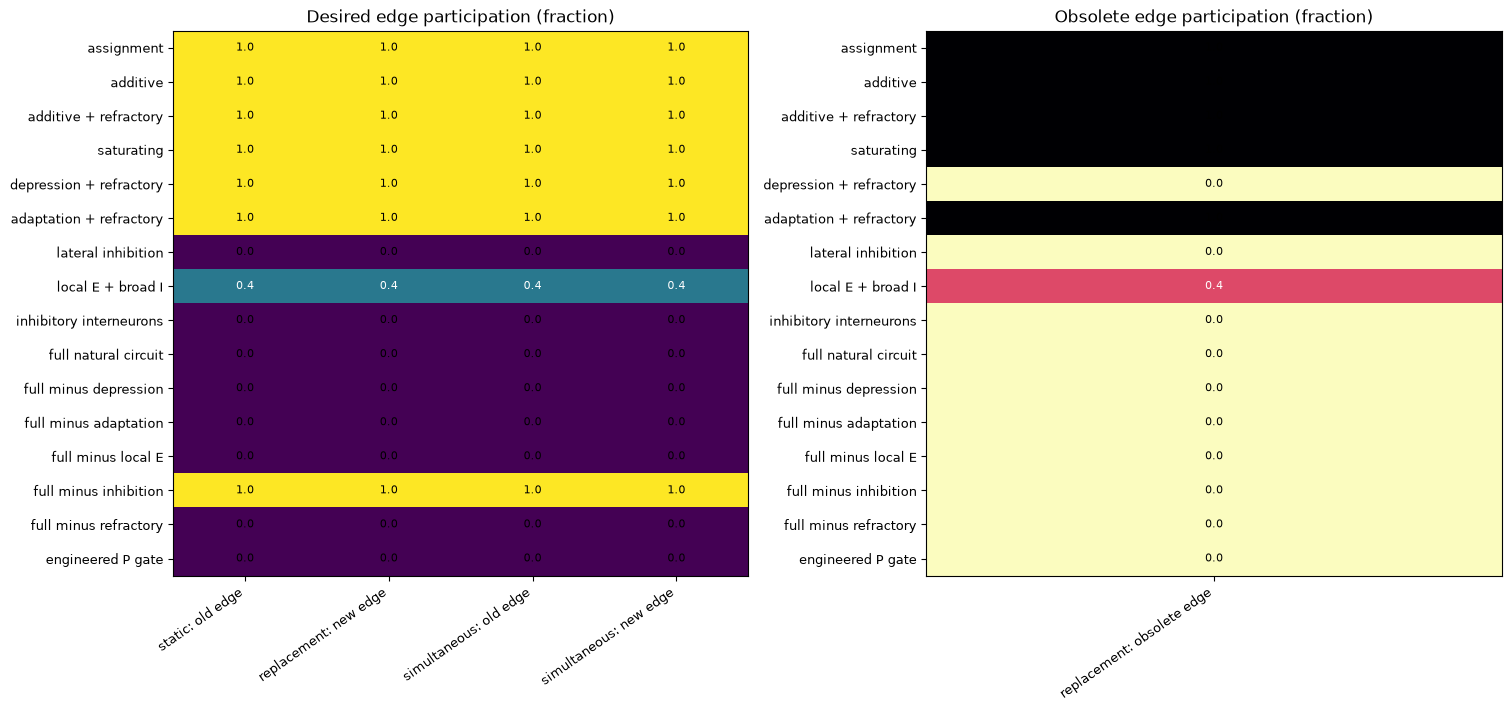

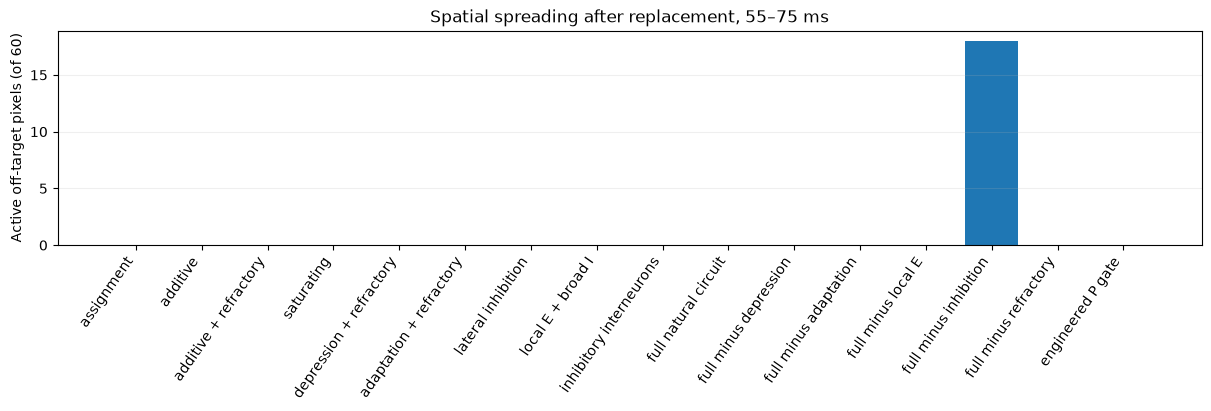

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), constrained_layout=True)
wanted = summary[["static: old edge", "replacement: new edge",
                  "simultaneous: old edge", "simultaneous: new edge"]]
unwanted = summary[["replacement: obsolete edge"]]
axes[0].imshow(wanted.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="viridis")
axes[1].imshow(unwanted.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="magma_r")
for ax, df, title in ((axes[0], wanted, "Desired edge participation (fraction)"),
                      (axes[1], unwanted, "Obsolete edge participation (fraction)")):
    ax.set_title(title)
    ax.set_yticks(np.arange(len(summary)), summary.index, fontsize=9)
    ax.set_xticks(np.arange(df.shape[1]), df.columns, rotation=35, ha="right", fontsize=9)
    for i in range(len(df)):
        for j in range(df.shape[1]):
            value = df.iloc[i, j]
            ax.text(j, i, f"{value:.1f}", ha="center", va="center",
                    color="white" if 0.2 < value < 0.8 else "black", fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.bar(np.arange(len(summary)), summary["replacement: other pixels"])
ax.set_xticks(np.arange(len(summary)), summary.index, rotation=55, ha="right")
ax.set(ylabel="Active off-target pixels (of 60)",
       title="Spatial spreading after replacement, 55–75 ms")
ax.grid(axis="y", alpha=0.2)
plt.show()

## 6. Examine complete spatiotemporal behavior

Summary counts cannot show **when** activity becomes persistent or which locations replace others. For representative mechanisms, plot a raster with old-edge, new-edge, and off-target spikes distinguished and a spatial heat map of **per-pixel spike counts** during 55–75 ms.

We include the original assignment rule, the combined natural circuit, the explicit gate comparator, and an ablation of inhibition. These are comparisons, not cherry-picked successes; the numeric table above still includes every model.

WARNING    'i' is an internal variable of group 'synapses', but also exists in the run namespace with the value 15. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'i' is an internal variable of group 'synapses_3', but also exists in the run namespace with the value 15. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


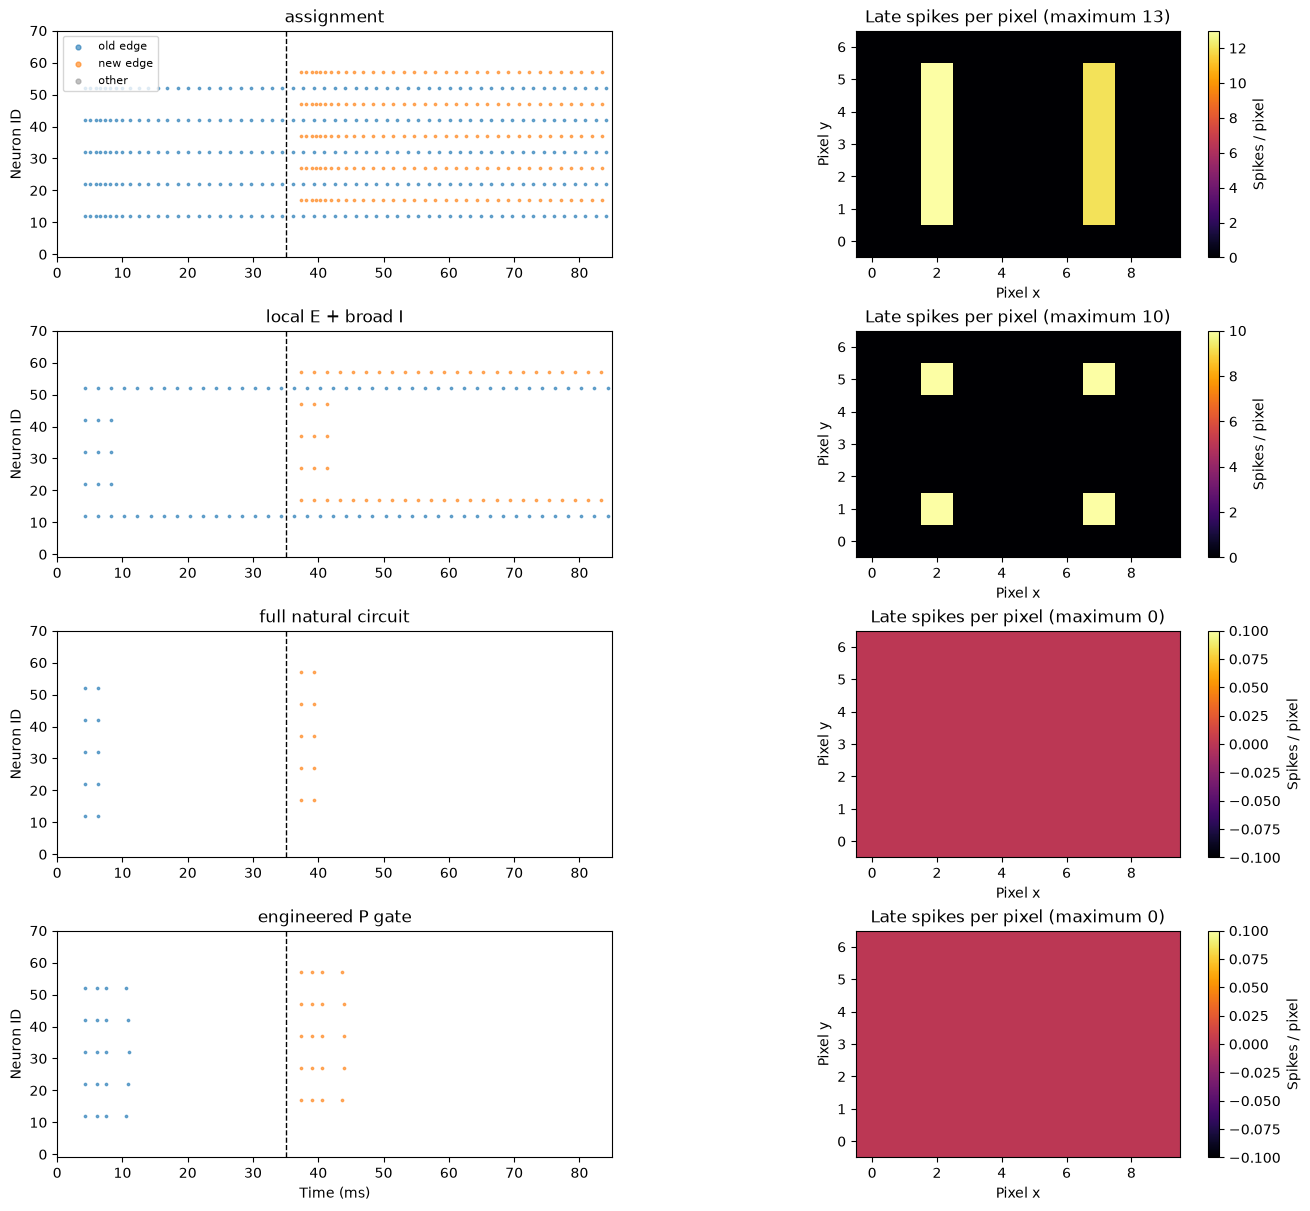

In [7]:
show = ("assignment", "local E + broad I", "full natural circuit", "engineered P gate")
fig, axes = plt.subplots(len(show), 2, figsize=(13, 12), constrained_layout=True)
for row, name in enumerate(show):
    r = simulate(variants[name], "replacement", 0.1)
    ax = axes[row, 0]
    for group, color, label in ((old_edge, "tab:blue", "old edge"),
                                (new_edge, "tab:orange", "new edge"),
                                (other, "0.6", "other")):
        mask = np.isin(r["i"], group)
        ax.scatter(r["t"][mask], r["i"][mask], s=3, alpha=0.6,
                   c=color, label=label)
    ax.axvline(35, color="black", linestyle="--", linewidth=1)
    ax.set(xlim=(0,total_ms), ylim=(-1,N), ylabel="Neuron ID", title=name)
    if row == 0:
        ax.legend(markerscale=2, fontsize=8)
    late = (r["t"] >= 55) & (r["t"] < 75)
    counts = np.bincount(r["i"][late], minlength=N).reshape(height, width)
    heat = axes[row, 1].imshow(counts, origin="lower", interpolation="nearest",
                                 cmap="inferno", vmin=0)
    axes[row, 1].set(title=f"Late spikes per pixel (maximum {counts.max()})",
                     xlabel="Pixel x", ylabel="Pixel y")
    fig.colorbar(heat, ax=axes[row, 1], label="Spikes / pixel")
axes[-1, 0].set_xlabel("Time (ms)")
plt.show()

## 7. Timestep refinement and numerical diagnostics

For representative alternatives, repeat the **identical replacement protocol** at 0.25, 0.1, 0.05, and 0.025 ms. Compare **late spike counts** and both old/new edge participation. A mechanism may have stable binary participation but a diverging firing rate, as notebook 12 showed; therefore, we must inspect both. Clock-based spike times need not match exactly between resolutions.

The finite-state check below is not an independent integrator validation. Notebook 12 independently verified the simple LIF + additive-synapse core, but the added adaptation, depression, interneuron, and gate mechanisms have **not** been independently reproduced in NumPy. Interpret their output as exploratory until verified separately.

Timestep refinement: 100%|██████████| 7/7 [00:07<00:00,  1.07s/it]


,model,dt_ms,late_spikes,new_fraction,old_fraction,off_target
0,assignment,0.250,120,1.0,1.0,0
1,assignment,0.100,125,1.0,1.0,0
2,assignment,0.050,120,1.0,1.0,0
3,assignment,0.025,125,1.0,1.0,0
4,additive,0.250,800,1.0,1.0,0
5,additive,0.100,2000,1.0,1.0,0
6,additive,0.050,4000,1.0,1.0,0
7,additive,0.025,8000,1.0,1.0,0
8,additive + refractory,0.250,100,1.0,1.0,0
9,additive + refractory,0.100,100,1.0,1.0,0


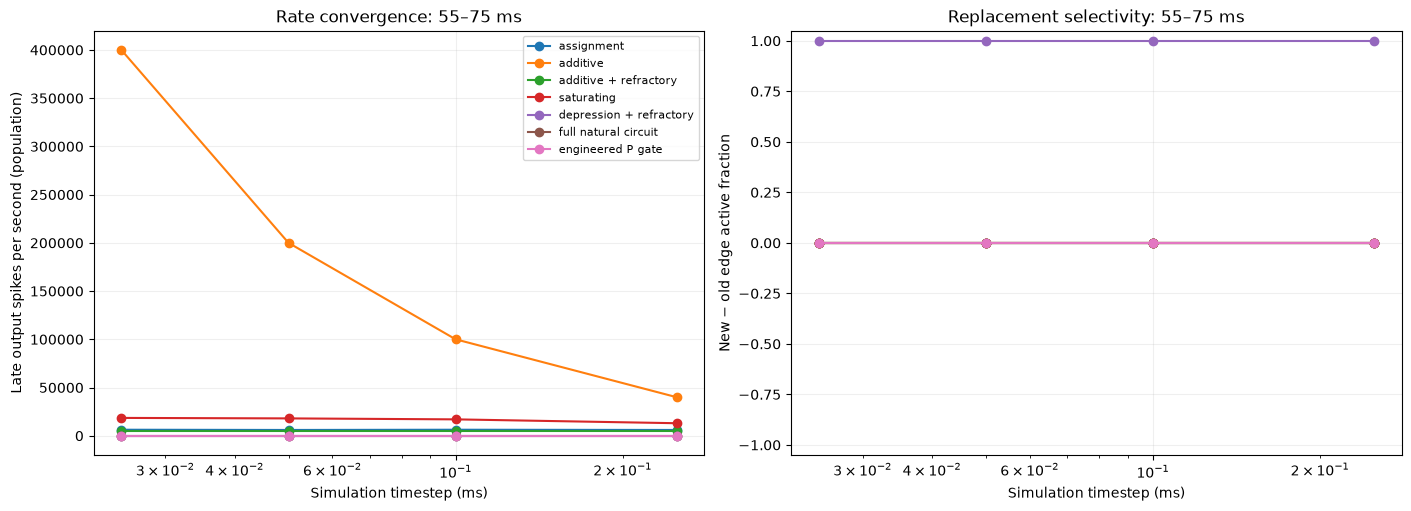

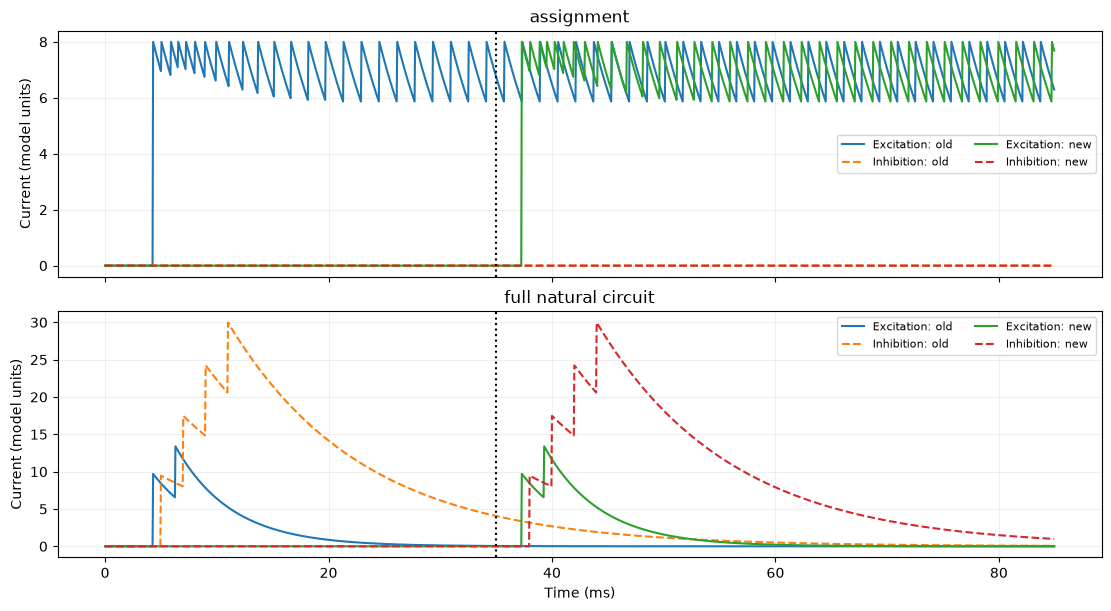

In [8]:
selected = ("assignment", "additive", "additive + refractory", "saturating",
            "depression + refractory", "full natural circuit", "engineered P gate")
convergence = []
for name in tqdm(selected, desc="Timestep refinement"):
    for dt_ms in (0.25, 0.1, 0.05, 0.025):
        r = simulate(variants[name], "replacement", dt_ms)
        s = active_set(r, 55, 75)
        late_count = int(np.count_nonzero((r["t"] >= 55) & (r["t"] < 75)))
        convergence.append(dict(model=name, dt_ms=dt_ms, late_spikes=late_count,
            new_fraction=len(s.intersection(new_edge))/len(new_edge),
            old_fraction=len(s.intersection(old_edge))/len(old_edge),
            off_target=len(s.intersection(other))))
conv = pd.DataFrame(convergence)
display(conv)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for name, group in conv.groupby("model", sort=False):
    group = group.sort_values("dt_ms")
    axes[0].plot(group.dt_ms, group.late_spikes/0.020,
                 marker="o", label=name)
    axes[1].plot(group.dt_ms, group.new_fraction-group.old_fraction,
                 marker="o", label=name)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Simulation timestep (ms)")
    ax.grid(alpha=0.2)
axes[0].set(ylabel="Late output spikes per second (population)",
            title="Rate convergence: 55–75 ms")
axes[1].set(ylabel="New − old edge active fraction",
            title="Replacement selectivity: 55–75 ms", ylim=(-1.05,1.05))
axes[0].legend(fontsize=8)
plt.show()

# Inspect actual currents on the center of old/new edges, not just spikes.
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
for ax, name in zip(axes, ("assignment", "full natural circuit")):
    r = simulate(variants[name], "replacement", 0.05, record=True)
    for idx, edge_label in ((0, "old"), (1, "new")):
        ax.plot(r["state_times"], r["states"]["Iexc"][idx],
                label=f"Excitation: {edge_label}")
        ax.plot(r["state_times"], r["states"]["Iinh"][idx],
                linestyle="--", label=f"Inhibition: {edge_label}")
    ax.axvline(35, color="black", linestyle=":")
    ax.set(ylabel="Current (model units)", title=name)
    ax.grid(alpha=0.2)
    ax.legend(ncol=2, fontsize=8)
axes[-1].set_xlabel("Time (ms)")
plt.show()

## 8. Interpretation: preserve all failures

Interpret the outputs in this order:

1. **Persistence:** does the static old edge remain active after input ends? Models without persistent activity cannot solve ESCM's memory problem.
2. **Replacement:** does the new edge become active after 35 ms and does the old edge become inactive? Successful inhibition that kills *both* is not replacement.
3. **Coexistence:** can both simultaneously stimulated edges persist, or does inhibition cause winner-take-all behavior?
4. **Spatial specificity:** are many unstimulated pixels recruited? The old/new-edge scores alone can hide this.
5. **Convergence:** do firing rates and spatial selectivity remain similar as the clock step is reduced? A refractory period can hide large excitatory currents behind an imposed firing-rate ceiling.
6. **Causality:** compare full natural circuit with each one-factor ablation. A failure when removing a component is evidence for its contribution **in this parameter regime**, not its necessity for all possible parameterizations.

**Avoid selecting a winner by a single heuristic score or tuning parameters to fit one protocol.** If the combined circuit fails, report the failure and use the ablations to identify which interaction is responsible. A biologically motivated component can worsen the target behavior, and that is a scientifically useful result.

**Next:** only after finding a bounded and reproducible regime should we replicate its update equations in an independent reference and test additional motion directions, speeds, widths, and event noise. The original ESCM should be evaluated separately under its historical parameters for a fair functional comparison.